# Exploratory Data Analysis and Data Quality

This notebook performs exploratory data analysis and data-quality assessment on the synchronized PVS1–PVS9 datasets.

The analysis examines dataset structure, data types, missing and invalid values, road-condition class distributions, speed characteristics, road-surface context, sensor measurements, and potential outliers.

The synchronized datasets generated during the data acquisition and synchronization stage are used as the input for this analysis.

In [3]:
# Import required libraries

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
# Mount Google Drive

from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# Check the synchronized data folder

import os

for pvs_number in range(1, 10):

    folder_path = (
        f"/content/drive/MyDrive/PVS{pvs_number}/Synced_Data"
    )

    print(f"\nPVS{pvs_number}")
    print("Folder exists:", os.path.exists(folder_path))

    if os.path.exists(folder_path):
        print("Files:")
        print(os.listdir(folder_path))


PVS1
Folder exists: True
Files:
['PVS_synced_master.csv', 'PVS1_synchronized.csv']

PVS2
Folder exists: True
Files:
['PVS2_synchronized.csv']

PVS3
Folder exists: True
Files:
['PVS3_synchronized.csv']

PVS4
Folder exists: True
Files:
['PVS4_synchronized.csv']

PVS5
Folder exists: True
Files:
['PVS5_synchronized.csv']

PVS6
Folder exists: True
Files:
['PVS6_synchronized.csv']

PVS7
Folder exists: True
Files:
['PVS7_synchronized.csv']

PVS8
Folder exists: True
Files:
['PVS8_synchronized.csv']

PVS9
Folder exists: True
Files:
['PVS9_synchronized.csv']


## 2. Load Synchronized Datasets

The synchronized datasets generated during the data acquisition and synchronization stage are loaded from the corresponding `Synced_Data` directories of PVS1–PVS9.

These datasets will be used as the input for exploratory data analysis and data-quality assessment.

In [6]:
# Load synchronized PVS1-PVS9 datasets

pvs_data = {}

for pvs_number in range(1, 10):

    file_path = (
        f"/content/drive/MyDrive/PVS{pvs_number}/"
        f"Synced_Data/PVS{pvs_number}_synchronized.csv"
    )

    pvs_data[pvs_number] = pd.read_csv(
        file_path
    )

    print(
        f"PVS{pvs_number}: "
        f"{pvs_data[pvs_number].shape}"
    )

PVS1: (144036, 60)
PVS2: (124684, 60)
PVS3: (105816, 60)
PVS4: (132492, 60)
PVS5: (133877, 60)
PVS6: (96279, 60)
PVS7: (128548, 60)
PVS8: (123618, 60)
PVS9: (91555, 60)


In [7]:
# Inspect the structure of PVS1

pvs_data[1].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144036 entries, 0 to 144035
Data columns (total 60 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   timestamp                      144036 non-null  float64
 1   left_acc_x_dashboard           144036 non-null  float64
 2   left_acc_y_dashboard           144036 non-null  float64
 3   left_acc_z_dashboard           144036 non-null  float64
 4   left_acc_x_above_suspension    144036 non-null  float64
 5   left_acc_y_above_suspension    144036 non-null  float64
 6   left_acc_z_above_suspension    144036 non-null  float64
 7   left_acc_x_below_suspension    144036 non-null  float64
 8   left_acc_y_below_suspension    144036 non-null  float64
 9   left_acc_z_below_suspension    144036 non-null  float64
 10  left_gyro_x_dashboard          144036 non-null  float64
 11  left_gyro_y_dashboard          144036 non-null  float64
 12  left_gyro_z_dashboard         

In [8]:
# Check missing values across all PVS datasets

missing_summary = []

for pvs_number, df in pvs_data.items():

    total_missing = df.isna().sum().sum()

    missing_summary.append({
        "Dataset": f"PVS{pvs_number}",
        "Rows": len(df),
        "Columns": df.shape[1],
        "Total Missing Values": total_missing
    })

missing_df = pd.DataFrame(
    missing_summary
)

missing_df

,Dataset,Rows,Columns,Total Missing Values
0,PVS1,144036,60,0
1,PVS2,124684,60,0
2,PVS3,105816,60,0
3,PVS4,132492,60,0
4,PVS5,133877,60,0
5,PVS6,96279,60,0
6,PVS7,128548,60,0
7,PVS8,123618,60,0
8,PVS9,91555,60,0


In [9]:
# Check infinite values across all numerical columns

numeric_inf_summary = []

for pvs_number, df in pvs_data.items():

    numeric_df = df.select_dtypes(
        include=np.number
    )

    positive_inf = np.isposinf(
        numeric_df
    ).sum().sum()

    negative_inf = np.isneginf(
        numeric_df
    ).sum().sum()

    total_inf = positive_inf + negative_inf

    numeric_inf_summary.append({
        "Dataset": f"PVS{pvs_number}",
        "Positive Infinity": positive_inf,
        "Negative Infinity": negative_inf,
        "Total Infinite Values": total_inf
    })

inf_df = pd.DataFrame(
    numeric_inf_summary
)

inf_df

,Dataset,Positive Infinity,Negative Infinity,Total Infinite Values
0,PVS1,0,0,0
1,PVS2,0,0,0
2,PVS3,0,0,0
3,PVS4,0,0,0
4,PVS5,0,0,0
5,PVS6,0,0,0
6,PVS7,0,0,0
7,PVS8,0,0,0
8,PVS9,0,0,0


In [10]:
# Analyze road-condition class distribution

class_distribution = []

for pvs_number, df in pvs_data.items():

    counts = df["road_condition"].value_counts()

    total = len(df)

    for condition in ["good", "regular", "bad"]:

        count = counts.get(condition, 0)

        percentage = (
            count / total
        ) * 100

        class_distribution.append({
            "Dataset": f"PVS{pvs_number}",
            "Road Condition": condition,
            "Count": count,
            "Percentage": round(
                percentage,
                2
            )
        })

class_distribution_df = pd.DataFrame(
    class_distribution
)

class_distribution_df

,Dataset,Road Condition,Count,Percentage
0,PVS1,good,56510,39.23
1,PVS1,regular,63388,44.01
2,PVS1,bad,24138,16.76
3,PVS2,good,55926,44.85
4,PVS2,regular,35893,28.79
5,PVS2,bad,32865,26.36
6,PVS3,good,50866,48.07
7,PVS3,regular,46027,43.50
8,PVS3,bad,8923,8.43
9,PVS4,good,50634,38.22


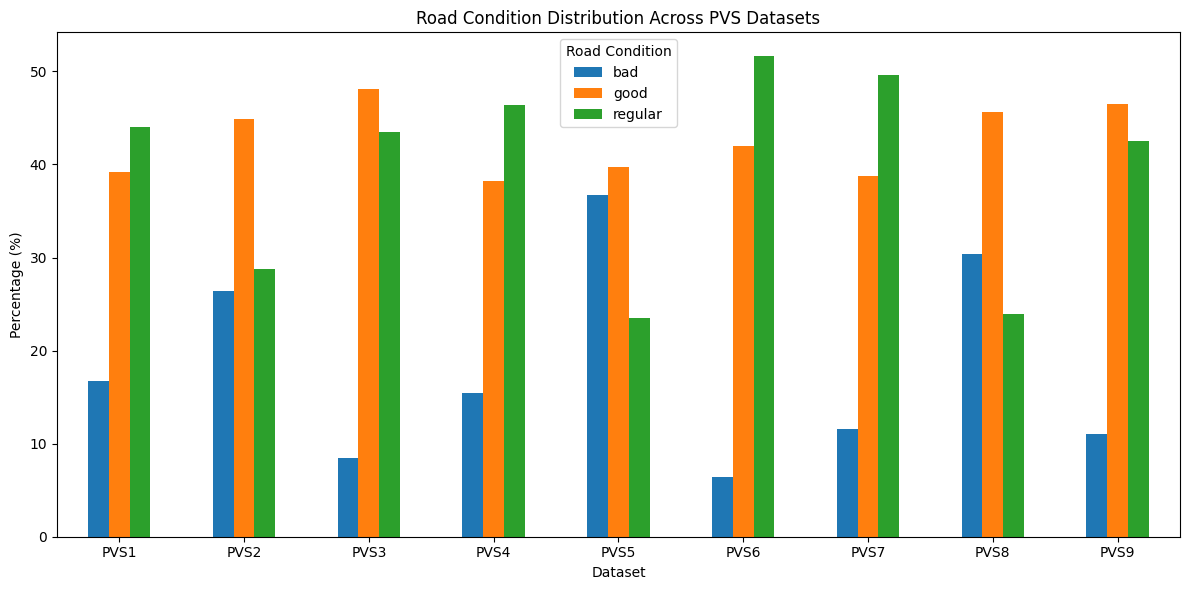

In [11]:
# Plot road-condition distribution across PVS datasets

pivot_distribution = class_distribution_df.pivot(
    index="Dataset",
    columns="Road Condition",
    values="Percentage"
)

pivot_distribution.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Road Condition Distribution Across PVS Datasets"
)

plt.xlabel("Dataset")
plt.ylabel("Percentage (%)")

plt.xticks(rotation=0)

plt.legend(
    title="Road Condition"
)

plt.tight_layout()

plt.show()

In [12]:
# Analyze speed characteristics across PVS datasets

speed_summary = []

for pvs_number, df in pvs_data.items():

    speed = df["speed"]

    speed_summary.append({
        "Dataset": f"PVS{pvs_number}",
        "Minimum Speed": speed.min(),
        "Maximum Speed": speed.max(),
        "Mean Speed": speed.mean(),
        "Median Speed": speed.median(),
        "Standard Deviation": speed.std()
    })

speed_summary_df = pd.DataFrame(
    speed_summary
)

speed_summary_df.round(3)

,Dataset,Minimum Speed,Maximum Speed,Mean Speed,Median Speed,Standard Deviation
0,PVS1,0.003,26.874,9.557,6.619,7.746
1,PVS2,0.006,21.592,9.239,6.692,6.298
2,PVS3,0.004,23.496,10.099,7.145,7.337
3,PVS4,0.011,26.536,10.388,7.432,7.520
4,PVS5,0.000,28.549,8.611,5.265,7.315
5,PVS6,0.000,28.299,11.084,6.576,8.418
6,PVS7,0.003,25.691,10.694,7.883,7.831
7,PVS8,0.000,26.643,9.327,6.814,6.641
8,PVS9,0.002,25.552,11.685,8.551,7.588


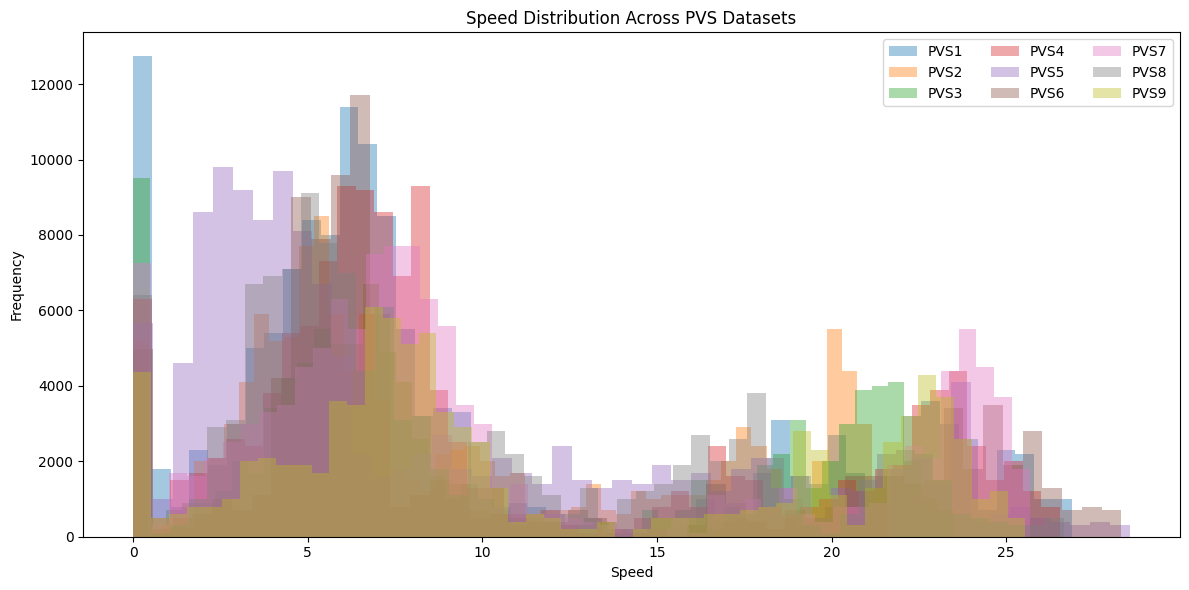

In [13]:
# Plot speed distributions across PVS datasets

plt.figure(figsize=(12, 6))

for pvs_number, df in pvs_data.items():

    plt.hist(
        df["speed"],
        bins=50,
        alpha=0.4,
        label=f"PVS{pvs_number}"
    )

plt.title(
    "Speed Distribution Across PVS Datasets"
)

plt.xlabel("Speed")
plt.ylabel("Frequency")

plt.legend(
    ncol=3
)

plt.tight_layout()

plt.show()

In [14]:
# Analyze sensor-group statistics for PVS1

sensor_groups = {
    "Accelerometer": [
        col for col in pvs_data[1].columns
        if "acc_" in col
    ],
    "Gyroscope": [
        col for col in pvs_data[1].columns
        if "gyro_" in col
    ],
    "Magnetometer": [
        col for col in pvs_data[1].columns
        if "mag_" in col
    ],
    "Temperature": [
        col for col in pvs_data[1].columns
        if "temp_" in col
    ]
}

sensor_summary = []

for group_name, columns in sensor_groups.items():

    values = pvs_data[1][columns]

    sensor_summary.append({
        "Sensor Group": group_name,
        "Number of Features": len(columns),
        "Mean": values.mean().mean(),
        "Minimum": values.min().min(),
        "Maximum": values.max().max(),
        "Standard Deviation": values.std().mean()
    })

sensor_summary_df = pd.DataFrame(
    sensor_summary
)

sensor_summary_df.round(4)

,Sensor Group,Number of Features,Mean,Minimum,Maximum,Standard Deviation
0,Accelerometer,18,3.2125,-77.7408,79.1632,2.7054
1,Gyroscope,18,0.0548,-316.6723,341.8665,9.1473
2,Magnetometer,12,-6.6717,-134.0843,137.8317,14.0535
3,Temperature,6,35.8055,0.0000,48.3160,1.8702


In [15]:
# Check zero values in temperature sensors

temperature_columns = [
    col for col in pvs_data[1].columns
    if "temp_" in col
]

temperature_zero_summary = []

for column in temperature_columns:

    zero_count = (
        pvs_data[1][column] == 0
    ).sum()

    total_count = len(
        pvs_data[1]
    )

    zero_percentage = (
        zero_count / total_count
    ) * 100

    temperature_zero_summary.append({
        "Column": column,
        "Zero Count": zero_count,
        "Zero Percentage": round(
            zero_percentage,
            2
        )
    })

temperature_zero_df = pd.DataFrame(
    temperature_zero_summary
)

temperature_zero_df

,Column,Zero Count,Zero Percentage
0,left_temp_dashboard,0,0.0
1,left_temp_above_suspension,0,0.0
2,left_temp_below_suspension,0,0.0
3,right_temp_dashboard,1,0.0
4,right_temp_above_suspension,1,0.0
5,right_temp_below_suspension,1,0.0


In [16]:
# Locate zero temperature observations

zero_temperature_rows = pvs_data[1][
    (pvs_data[1]["right_temp_dashboard"] == 0) |
    (pvs_data[1]["right_temp_above_suspension"] == 0) |
    (pvs_data[1]["right_temp_below_suspension"] == 0)
]

zero_temperature_rows[
    [
        "timestamp",
        "right_temp_dashboard",
        "right_temp_above_suspension",
        "right_temp_below_suspension"
    ]
]

,timestamp,right_temp_dashboard,right_temp_above_suspension,right_temp_below_suspension
71273,1.577220e+09,0.000000,22.145251,17.305044
71274,1.577220e+09,17.736349,0.000000,0.000000


In [17]:
# Detect potential accelerometer outliers using the IQR method

accelerometer_columns = [
    col for col in pvs_data[1].columns
    if "acc_" in col
]

accelerometer_outliers = []

for column in accelerometer_columns:

    series = pvs_data[1][column]

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (series < lower_bound) |
        (series > upper_bound)
    ).sum()

    outlier_percentage = (
        outlier_count / len(series)
    ) * 100

    accelerometer_outliers.append({
        "Column": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Potential Outliers": outlier_count,
        "Outlier Percentage": round(
            outlier_percentage,
            3
        )
    })

accelerometer_outlier_df = pd.DataFrame(
    accelerometer_outliers
)

accelerometer_outlier_df.sort_values(
    "Outlier Percentage",
    ascending=False
)

,Column,Lower Bound,Upper Bound,Potential Outliers,Outlier Percentage
16,right_acc_y_below_suspension,-7.559546,7.705884,20568,14.280
7,left_acc_y_below_suspension,-7.092594,7.301346,19727,13.696
1,left_acc_y_dashboard,-3.332429,3.342605,13326,9.252
10,right_acc_y_dashboard,-3.278380,3.377500,13216,9.175
17,right_acc_z_below_suspension,-2.631155,22.062641,13188,9.156
8,left_acc_z_below_suspension,-0.482090,20.060161,13137,9.121
15,right_acc_x_below_suspension,-4.342381,3.989441,13048,9.059
2,left_acc_z_dashboard,6.476794,12.950716,12594,8.744
11,right_acc_z_dashboard,6.448842,13.071204,11850,8.227
6,left_acc_x_below_suspension,-3.658084,3.098353,11220,7.790


In [18]:
# Detect potential gyroscope outliers using the IQR method

gyroscope_columns = [
    col for col in pvs_data[1].columns
    if "gyro_" in col
]

gyroscope_outliers = []

for column in gyroscope_columns:

    series = pvs_data[1][column]

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (series < lower_bound) |
        (series > upper_bound)
    ).sum()

    outlier_percentage = (
        outlier_count / len(series)
    ) * 100

    gyroscope_outliers.append({
        "Column": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Potential Outliers": outlier_count,
        "Outlier Percentage": round(
            outlier_percentage,
            3
        )
    })

gyroscope_outlier_df = pd.DataFrame(
    gyroscope_outliers
)

gyroscope_outlier_df.sort_values(
    "Outlier Percentage",
    ascending=False
)

,Column,Lower Bound,Upper Bound,Potential Outliers,Outlier Percentage
0,left_gyro_x_dashboard,-6.214523,6.053543,19689,13.669
17,right_gyro_z_below_suspension,-18.920712,18.921085,16350,11.351
11,right_gyro_z_dashboard,-4.650879,4.748535,16193,11.242
8,left_gyro_z_below_suspension,-18.388657,18.598647,16117,11.190
9,right_gyro_x_dashboard,-7.484627,7.530022,15477,10.745
2,left_gyro_z_dashboard,-4.912567,4.853058,15165,10.529
5,left_gyro_z_above_suspension,-4.985902,4.901793,15038,10.440
14,right_gyro_z_above_suspension,-5.176823,4.955013,14676,10.189
10,right_gyro_y_dashboard,-12.279320,12.378883,14222,9.874
12,right_gyro_x_above_suspension,-5.492048,5.616351,14090,9.782


In [19]:
# Detect potential magnetometer outliers using the IQR method

magnetometer_columns = [
    col for col in pvs_data[1].columns
    if "mag_" in col
]

magnetometer_outliers = []

for column in magnetometer_columns:

    series = pvs_data[1][column]

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (series < lower_bound) |
        (series > upper_bound)
    ).sum()

    outlier_percentage = (
        outlier_count / len(series)
    ) * 100

    magnetometer_outliers.append({
        "Column": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Potential Outliers": outlier_count,
        "Outlier Percentage": round(
            outlier_percentage,
            3
        )
    })

magnetometer_outlier_df = pd.DataFrame(
    magnetometer_outliers
)

magnetometer_outlier_df.sort_values(
    "Outlier Percentage",
    ascending=False
)

,Column,Lower Bound,Upper Bound,Potential Outliers,Outlier Percentage
5,left_mag_z_above_suspension,-18.547897,10.914466,23673,16.435
11,right_mag_z_above_suspension,-163.983514,-77.676401,18176,12.619
9,right_mag_x_above_suspension,-79.185671,82.969287,7078,4.914
8,right_mag_z_dashboard,-3.302666,7.734091,696,0.483
2,left_mag_z_dashboard,-2.531274,6.790243,443,0.308
4,left_mag_y_above_suspension,-73.891789,15.371866,37,0.026
0,left_mag_x_dashboard,-52.288063,65.163246,0,0.000
1,left_mag_y_dashboard,-42.562358,13.196189,0,0.000
3,left_mag_x_above_suspension,3.014860,119.323059,0,0.000
6,right_mag_x_dashboard,-49.711513,60.387811,0,0.000


In [20]:
# Calculate accelerometer correlation matrix for PVS1

accelerometer_columns = [
    col for col in pvs_data[1].columns
    if "acc_" in col
]

acceleration_correlation = (
    pvs_data[1][accelerometer_columns]
    .corr()
)

acceleration_correlation.round(2)

,left_acc_x_dashboard,left_acc_y_dashboard,left_acc_z_dashboard,left_acc_x_above_suspension,left_acc_y_above_suspension,left_acc_z_above_suspension,left_acc_x_below_suspension,left_acc_y_below_suspension,left_acc_z_below_suspension,right_acc_x_dashboard,right_acc_y_dashboard,right_acc_z_dashboard,right_acc_x_above_suspension,right_acc_y_above_suspension,right_acc_z_above_suspension,right_acc_x_below_suspension,right_acc_y_below_suspension,right_acc_z_below_suspension
left_acc_x_dashboard,1.00,0.03,-0.09,0.55,0.10,0.27,0.08,0.02,-0.06,0.20,-0.00,0.01,0.22,-0.01,0.00,0.12,-0.00,-0.01
left_acc_y_dashboard,0.03,1.00,0.23,-0.02,0.54,-0.08,-0.05,-0.05,-0.04,-0.00,0.14,-0.05,-0.01,0.19,-0.03,0.00,0.04,-0.01
left_acc_z_dashboard,-0.09,0.23,1.00,0.12,-0.08,0.31,0.03,0.09,0.04,0.00,-0.05,0.10,-0.00,-0.06,0.10,-0.01,0.00,0.04
left_acc_x_above_suspension,0.55,-0.02,0.12,1.00,0.15,0.21,0.25,-0.09,0.04,0.22,-0.04,0.04,0.23,-0.05,0.03,0.11,-0.01,0.01
left_acc_y_above_suspension,0.10,0.54,-0.08,0.15,1.00,0.09,0.13,-0.06,-0.04,0.02,0.20,-0.04,0.02,0.26,-0.02,0.03,0.06,-0.02
left_acc_z_above_suspension,0.27,-0.08,0.31,0.21,0.09,1.00,-0.07,0.17,0.07,-0.05,-0.01,0.10,-0.06,-0.02,0.11,-0.02,0.00,0.04
left_acc_x_below_suspension,0.08,-0.05,0.03,0.25,0.13,-0.07,1.00,0.19,-0.03,0.15,0.02,-0.01,0.16,0.03,-0.03,0.07,0.01,0.00
left_acc_y_below_suspension,0.02,-0.05,0.09,-0.09,-0.06,0.17,0.19,1.00,-0.16,0.01,0.05,0.02,-0.01,0.07,0.01,-0.02,0.01,0.01
left_acc_z_below_suspension,-0.06,-0.04,0.04,0.04,-0.04,0.07,-0.03,-0.16,1.00,-0.01,-0.01,0.02,-0.00,-0.01,0.02,0.01,0.01,-0.01
right_acc_x_dashboard,0.20,-0.00,0.00,0.22,0.02,-0.05,0.15,0.01,-0.01,1.00,0.01,-0.10,0.62,-0.02,-0.36,0.01,-0.07,0.05


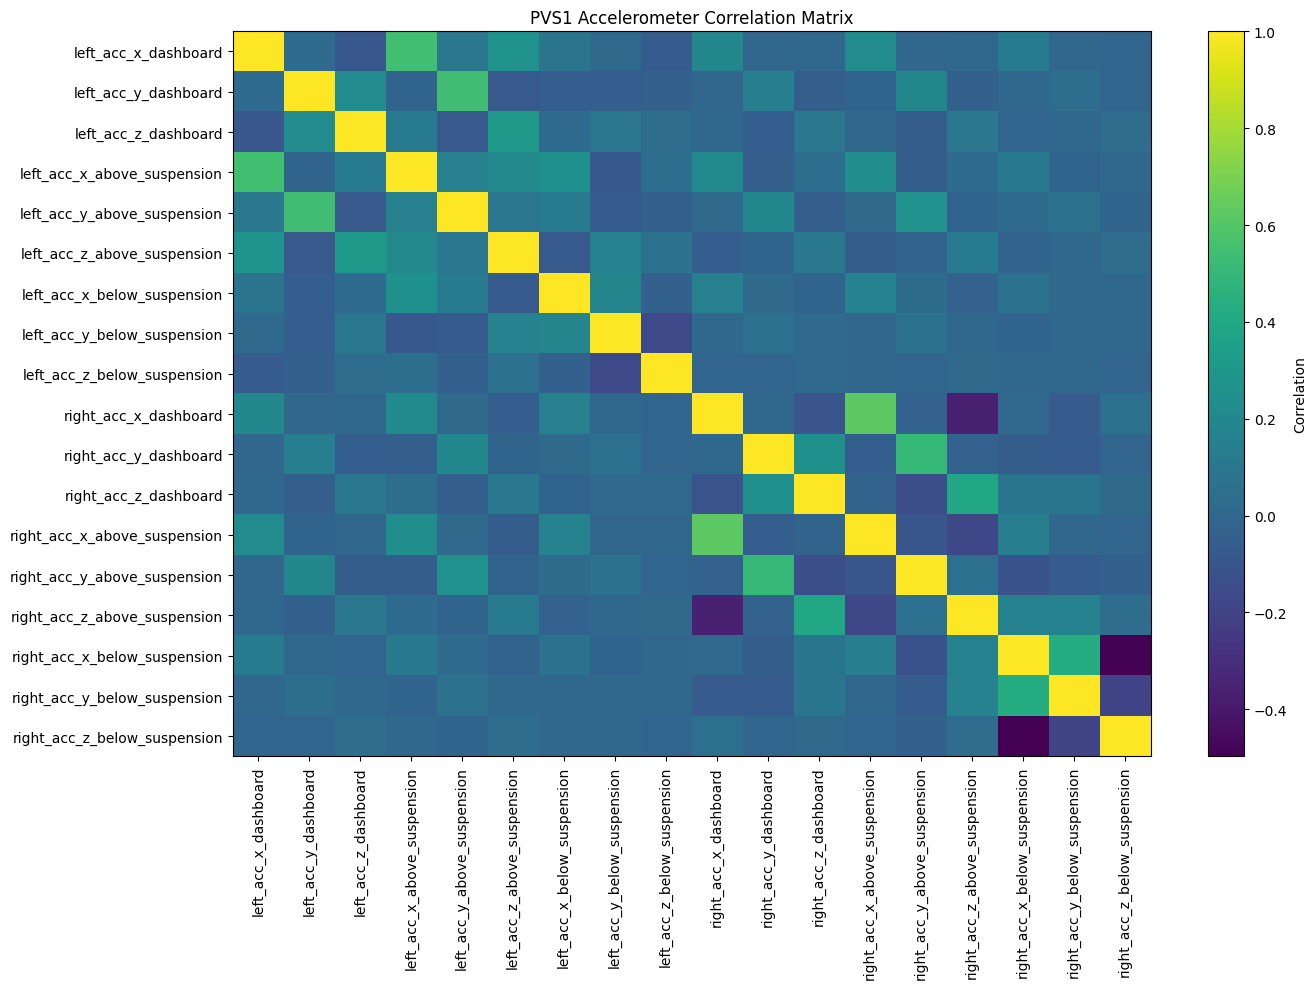

In [21]:
# Visualize accelerometer correlations for PVS1

plt.figure(figsize=(14, 10))

plt.imshow(
    acceleration_correlation,
    aspect="auto"
)

plt.colorbar(
    label="Correlation"
)

plt.xticks(
    range(len(accelerometer_columns)),
    accelerometer_columns,
    rotation=90
)

plt.yticks(
    range(len(accelerometer_columns)),
    accelerometer_columns
)

plt.title(
    "PVS1 Accelerometer Correlation Matrix"
)

plt.tight_layout()

plt.show()

In [22]:
# Create an overall data-quality summary for PVS1-PVS9

data_quality_summary = []

for pvs_number, df in pvs_data.items():

    numeric_df = df.select_dtypes(
        include=np.number
    )

    total_missing = (
        df.isna()
        .sum()
        .sum()
    )

    total_infinite = (
        np.isinf(numeric_df)
        .sum()
        .sum()
    )

    duplicate_rows = (
        df.duplicated()
        .sum()
    )

    timestamp_sorted = (
        df["timestamp"]
        .is_monotonic_increasing
    )

    class_percentages = (
        df["road_condition"]
        .value_counts(
            normalize=True
        )
        .mul(100)
    )

    data_quality_summary.append({
        "Dataset": f"PVS{pvs_number}",
        "Rows": len(df),
        "Columns": df.shape[1],
        "Missing Values": total_missing,
        "Infinite Values": total_infinite,
        "Duplicate Rows": duplicate_rows,
        "Timestamp Sorted": timestamp_sorted,
        "Good (%)": round(
            class_percentages.get("good", 0),
            2
        ),
        "Regular (%)": round(
            class_percentages.get("regular", 0),
            2
        ),
        "Bad (%)": round(
            class_percentages.get("bad", 0),
            2
        )
    })

data_quality_df = pd.DataFrame(
    data_quality_summary
)

data_quality_df

,Dataset,Rows,Columns,Missing Values,Infinite Values,Duplicate Rows,Timestamp Sorted,Good (%),Regular (%),Bad (%)
0,PVS1,144036,60,0,0,0,True,39.23,44.01,16.76
1,PVS2,124684,60,0,0,0,True,44.85,28.79,26.36
2,PVS3,105816,60,0,0,0,True,48.07,43.50,8.43
3,PVS4,132492,60,0,0,0,True,38.22,46.34,15.45
4,PVS5,133877,60,0,0,0,True,39.78,23.53,36.69
5,PVS6,96279,60,0,0,0,True,41.95,51.62,6.43
6,PVS7,128548,60,0,0,0,True,38.77,49.66,11.56
7,PVS8,123618,60,0,0,0,True,45.63,23.97,30.40
8,PVS9,91555,60,0,0,0,True,46.48,42.49,11.03


## 9. EDA Summary

The exploratory data analysis confirmed that the synchronized PVS1–PVS9 datasets contain consistent 60-column structures with no missing values, infinite values, or duplicate rows, and all datasets maintain chronological timestamp ordering.

The road-condition target shows varying class distributions across the PVS datasets, indicating differences in the representation of Good, Regular, and Bad road conditions across vehicle-driver contexts.

Speed distributions also vary across datasets, with observations ranging from very low speeds to higher operating speeds. These variations were retained because they may represent genuine driving conditions.

Potential outliers were identified in accelerometer, gyroscope, and magnetometer signals using the IQR method. These observations were not removed because extreme sensor responses may represent genuine vehicle and road-surface dynamics.

A preliminary accelerometer correlation analysis on PVS1 showed several moderate relationships between sensor measurements, while many feature pairs showed weak linear correlation. Therefore, feature removal was not performed during EDA. Feature selection will be addressed during the feature-engineering and modelling stages.

The EDA findings provide the basis for subsequent preprocessing, window-based feature extraction, feature selection, and machine-learning model development.

## 10. Noise Sources and Vehicle-Driver Dependency Analysis

The previous sections confirmed that the synchronized data are complete and consistent. This section examines the data from a different angle: **which parts of the recorded signals are not caused by the road surface**, and **which signal properties depend on the vehicle-driver context**. The findings define the noise-handling and dependency-handling steps applied in Notebook 03 and Notebook 05.

The analysis uses the `pvs_data` dictionary loaded in Section 2 and the shared pipeline module `c4_pipeline.py` (stored in `MyDrive/PVS_Code`).

In [23]:
# Import the shared Component 4 pipeline module
import os, sys, importlib
CODE_DIR = os.path.join(os.environ.get('C4_DRIVE', '/content/drive/MyDrive'), 'PVS_Code')
sys.path.insert(0, CODE_DIR)
import c4_pipeline as c4
importlib.reload(c4)

from scipy import signal

vehicle_of = {n: c4.PVS_META[n][0] for n in pvs_data}
driver_of = {n: c4.PVS_META[n][1] for n in pvs_data}
print('Vehicle-driver contexts:')
display(pd.DataFrame({n: c4.PVS_META[n] for n in pvs_data}, index=['Vehicle', 'Driver', 'Scenario']).T)

Vehicle-driver contexts:


,Vehicle,Driver,Scenario
1,VW Saveiro,Driver 1,1
2,VW Saveiro,Driver 1,2
3,VW Saveiro,Driver 1,3
4,Fiat Bravo,Driver 2,1
5,Fiat Bravo,Driver 2,2
6,Fiat Bravo,Driver 2,3
7,Fiat Palio,Driver 3,1
8,Fiat Palio,Driver 3,2
9,Fiat Palio,Driver 3,3


### 10.1 Driver behaviour: speed by road condition
If drivers slow down on bad roads, speed becomes a shortcut for the road class. Because vibration amplitude also grows with speed, a model can learn "slow = bad" or "fast = good" instead of the road surface itself, and that shortcut fails for a driver, vehicle or route with different driving habits.

**Result:** speed depends strongly on the road class (median ≈ 19–21 m/s on good roads, ≈ 6–7 m/s on regular and ≈ 4.5 m/s on bad roads) and only slightly on the driver (regular-road medians 6.1–7.2 m/s). Good roads in PVS are mostly faster road segments, so speed mainly encodes the **route context**. Raw speed is therefore not used as a feature, and amplitude features are speed-normalised (Notebook 05).

Condition,good,regular,bad
Vehicle,,,
Fiat Bravo,20.53,6.06,4.68
Fiat Palio,20.05,7.24,4.49
VW Saveiro,18.74,6.38,4.61


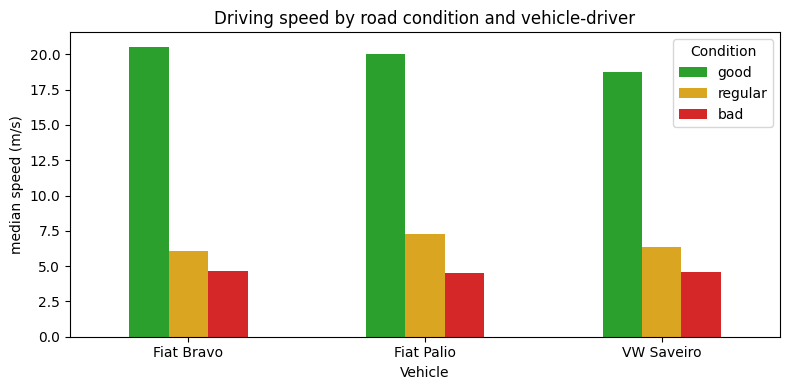

In [24]:
# Median speed (m/s) per vehicle-driver and road condition
speed_rows = []
for n, df in pvs_data.items():
    for cond in ['good', 'regular', 'bad']:
        s = df.loc[df['road_condition'] == cond, 'speed']
        speed_rows.append({'Dataset': f'PVS{n}', 'Vehicle': vehicle_of[n], 'Condition': cond,
                           'Median speed (m/s)': s.median()})
speed_by_class = pd.DataFrame(speed_rows)
display(speed_by_class.pivot_table(index='Vehicle', columns='Condition',
                                   values='Median speed (m/s)', aggfunc='median')[['good', 'regular', 'bad']].round(2))

speed_by_class.pivot_table(index='Vehicle', columns='Condition', values='Median speed (m/s)',
                           aggfunc='median')[['good', 'regular', 'bad']].plot(kind='bar', figsize=(8, 4), rot=0,
                           color=['tab:green', 'goldenrod', 'tab:red'])
plt.ylabel('median speed (m/s)'); plt.title('Driving speed by road condition and vehicle-driver')
plt.tight_layout(); plt.show()

### 10.2 Stationary periods and speed bumps
Stationary periods contain no road excitation; their vibration is engine and body vibration only. Speed bumps are road furniture, not roughness. Both are noise for this task.

In [25]:
# Share of stationary samples and speed-bump samples per dataset
rows = []
for n, df in pvs_data.items():
    extras = c4.load_raw_label_extras(n, len(df))
    rows.append({'Dataset': f'PVS{n}', 'Vehicle': vehicle_of[n],
                 'Stationary (< 0.3 m/s) %': 100 * (df['speed'] < 0.3).mean(),
                 'Slow (< 1 m/s) %': 100 * (df['speed'] < 1.0).mean(),
                 'Speed bump %': 100 * extras['bump'].mean() if extras is not None else np.nan})
display(pd.DataFrame(rows).round(2))

,Dataset,Vehicle,Stationary (< 0.3 m/s) %,Slow (< 1 m/s) %,Speed bump %
0,PVS1,VW Saveiro,8.63,10.02,2.40
1,PVS2,VW Saveiro,4.16,4.24,1.61
2,PVS3,VW Saveiro,8.99,9.37,0.58
3,PVS4,Fiat Bravo,4.52,5.05,2.37
4,PVS5,Fiat Bravo,4.17,4.61,1.45
5,PVS6,Fiat Bravo,5.07,5.38,0.63
6,PVS7,Fiat Palio,5.56,5.87,2.24
7,PVS8,Fiat Palio,5.11,5.27,1.49
8,PVS9,Fiat Palio,4.54,5.19,0.70


### 10.3 Sensor orientation and gravity
The mean acceleration of each axis shows how gravity is distributed over the sensor axes, and the tilt from vertical shows how each sensor is mounted.

**Result:** in PVS the dashboard sensors of all three vehicles are mounted almost identically (tilt from vertical 2.1–2.8°), so sensor orientation is **not** a major source of vehicle dependency in this dataset. Gravity removal is still required because the mean of a raw axis mostly measures gravity, not road vibration. Orientation-invariant channels are used mainly for deployment: a smartphone in a holder has an arbitrary and changing orientation.

In [26]:
# Mean acceleration per axis (gravity distribution) for the dashboard sensors
rows = []
for n, df in pvs_data.items():
    for side in ['left', 'right']:
        cols = c4.sensor_cols(f'{side}_dashboard', 'acc')
        m = df[cols].mean().values
        rows.append({'Dataset': f'PVS{n}', 'Vehicle': vehicle_of[n], 'Sensor': f'{side}_dashboard',
                     'mean acc_x': m[0], 'mean acc_y': m[1], 'mean acc_z': m[2],
                     'tilt from vertical (deg)': np.degrees(np.arccos(abs(m[2]) / np.linalg.norm(m)))})
orientation = pd.DataFrame(rows)
display(orientation.groupby(['Vehicle', 'Sensor']).mean(numeric_only=True).round(3))

mean acc_x  mean acc_y  mean acc_z  \
Vehicle    Sensor                                                
Fiat Bravo left_dashboard        0.273      -0.146       9.785   
           right_dashboard       0.279      -0.152       9.848   
Fiat Palio left_dashboard        0.271      -0.151       9.829   
           right_dashboard       0.247      -0.122       9.842   
VW Saveiro left_dashboard        0.255      -0.153       9.794   
           right_dashboard       0.207      -0.145       9.819   

                            tilt from vertical (deg)  
Vehicle    Sensor                                     
Fiat Bravo left_dashboard                      2.297  
           right_dashboard                     2.090  
Fiat Palio left_dashboard                      2.639  
           right_dashboard                     2.750  
VW Saveiro left_dashboard                      2.391  
           right_dashboard                     2.191

### 10.4 Magnetometer and temperature
The magnetometer measures the Earth's magnetic field, which depends on the **driving direction** and on magnetic disturbances inside each vehicle. Temperature depends on the **time of day, weather and engine heat**. Neither is caused by road roughness, so features from these sensors can only act as shortcuts that identify the trip or vehicle.

,Dataset,Vehicle,temp dashboard (mean),temp below susp. (mean),mag_y above susp. (mean),mag_y above susp. (std)
0,PVS1,VW Saveiro,35.91,32.72,-28.29,12.93
1,PVS2,VW Saveiro,32.83,31.75,15.57,17.79
2,PVS3,VW Saveiro,31.93,30.96,9.10,9.91
3,PVS4,Fiat Bravo,33.08,39.62,-21.50,9.83
4,PVS5,Fiat Bravo,27.25,41.10,43.96,44.24
5,PVS6,Fiat Bravo,26.31,37.49,-2.21,8.18
6,PVS7,Fiat Palio,33.51,35.70,-4.16,6.48
7,PVS8,Fiat Palio,30.53,34.31,-24.34,28.54
8,PVS9,Fiat Palio,29.92,32.69,-27.62,35.18


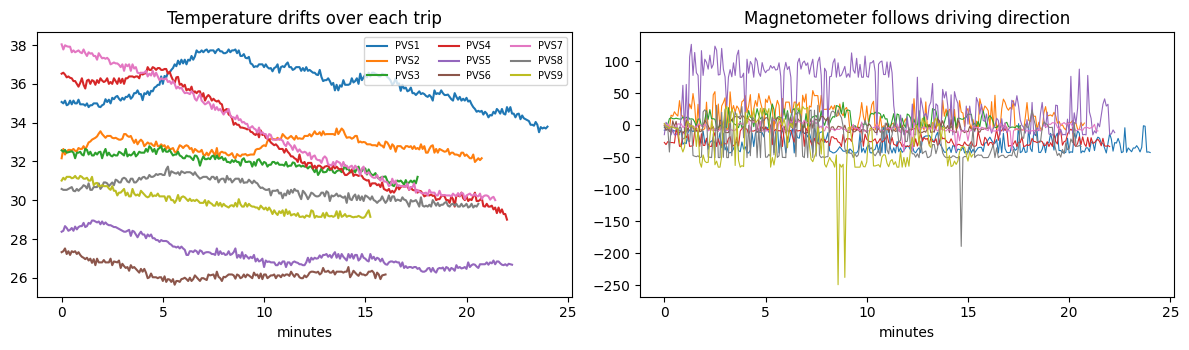

In [27]:
# Temperature and magnetometer level per dataset
rows = []
for n, df in pvs_data.items():
    rows.append({'Dataset': f'PVS{n}', 'Vehicle': vehicle_of[n],
                 'temp dashboard (mean)': df['left_temp_dashboard'].mean(),
                 'temp below susp. (mean)': df['left_temp_below_suspension'].mean(),
                 'mag_y above susp. (mean)': df['left_mag_y_above_suspension'].mean(),
                 'mag_y above susp. (std)': df['left_mag_y_above_suspension'].std()})
env = pd.DataFrame(rows)
display(env.round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for n, df in pvs_data.items():
    ax[0].plot(np.arange(len(df))[::500] / 6000, df['left_temp_dashboard'].values[::500], label=f'PVS{n}')
    ax[1].plot(np.arange(len(df))[::500] / 6000, df['left_mag_y_above_suspension'].values[::500], lw=.8)
ax[0].set_title('Temperature drifts over each trip'); ax[0].set_xlabel('minutes'); ax[0].legend(ncol=3, fontsize=7)
ax[1].set_title('Magnetometer follows driving direction'); ax[1].set_xlabel('minutes')
plt.tight_layout(); plt.show()

### 10.5 Vehicle vibration without road input
The power spectral density of the dashboard acceleration magnitude during stationary periods shows the vibration each vehicle produces with no road input (engine and body). This vehicle-specific noise floor is later subtracted from every window's spectrum.

**Result:** the VW Saveiro and the Fiat Bravo show a strong narrow peak near 28 Hz (engine idle vibration), while the Fiat Palio has no clear peak but a higher broadband floor between 3 and 25 Hz. These differences are produced by the vehicle, not by the road, and would otherwise appear as vehicle-specific spectral features.

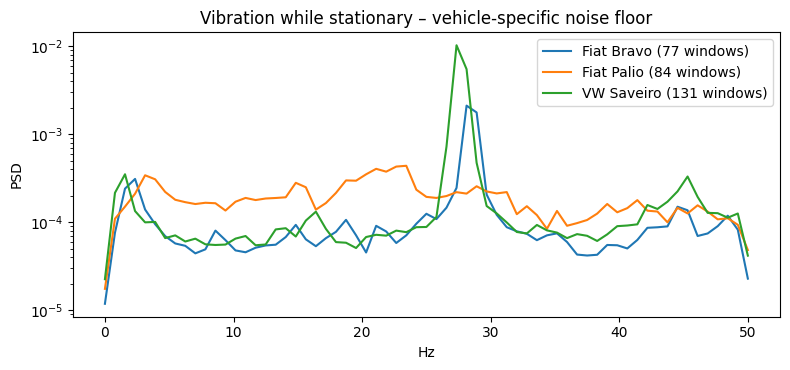

In [28]:
# Stationary vibration spectrum per vehicle (left dashboard)
plt.figure(figsize=(8, 3.8))
for vehicle in sorted(set(vehicle_of.values())):
    psds = []
    for n, df in pvs_data.items():
        if vehicle_of[n] != vehicle:
            continue
        acc = df[c4.sensor_cols('left_dashboard', 'acc')].values
        mag = np.linalg.norm(acc, axis=1); mag = mag - np.median(mag)
        still = (df['speed'].values < 0.3)
        runs = np.flatnonzero(np.diff(np.r_[0, still.astype(int), 0]))
        for a, b in zip(runs[::2], runs[1::2]):
            for st in range(a, b - 200, 200):
                f, p = signal.welch(mag[st:st + 200], fs=100, nperseg=128)
                psds.append(p)
    if psds:
        plt.semilogy(f, np.median(psds, axis=0), label=f'{vehicle} ({len(psds)} windows)')
plt.xlabel('Hz'); plt.ylabel('PSD'); plt.title('Vibration while stationary – vehicle-specific noise floor')
plt.legend(); plt.tight_layout(); plt.show()

### 10.6 Decisions Derived from the Noise and Dependency Analysis

| Finding | Consequence for the pipeline |
|---|---|
| Speed depends strongly on road class (route context) and slightly on the driver | raw speed removed as a feature; speed normalisation of amplitude features (Notebook 05) |
| Stationary periods exist in every trip | windows below 1 m/s excluded; stationary windows used to estimate the vehicle noise profile (Notebooks 03–04) |
| Speed bumps occur in every trip | windows containing speed bumps excluded (Notebook 03) |
| Raw axis means mostly measure gravity; sensor tilt is similar across PVS vehicles (≈ 2–3°) but arbitrary for a smartphone | gravity removal and orientation-invariant channels; means of raw (gravity-including) axes not used (Notebook 03) |
| Magnetometer and temperature are not road-related (e.g. the Fiat Bravo's below-suspension sensor runs warmer, ≈ 37–41 °C vs ≈ 31–36 °C) | magnetometer and temperature excluded from all features (Notebook 04) |
| Each vehicle has its own vibration noise floor (≈ 28 Hz idle peak for VW Saveiro and Fiat Bravo; higher broadband floor for Fiat Palio) | per-trip noise-profile spectral subtraction (Notebook 04) and per-trip normalisation (Notebook 05) |
| IQR outliers are mostly genuine road events | outliers are **not** removed; the Hampel filter is used only as a diagnostic, and only full-scale sensor glitches (saturation) are replaced (Notebook 03) |